# Question 5: what did the fastest-rising ZIPs look like a year before they took off?

A ZIP is **hot** in a year when its ZHVI growth over the next 12 months lands in the top 20% of ZIPs in its metro, the
Phase 14 target. Snapshots are taken every January from 2016 to 2025, so each window ends by January 2026 and is already
known. Each feature is the ZIP's value in the snapshot month, standardized within its metro and month, so a difference of
+0.5 means hot ZIPs sat half a standard deviation above their metro's typical ZIP. Source: `gold.mart_zip_month`.

Caveats: features are not yet shifted by their publication lags (Phase 11 does that); ACS income and population in
particular are published a year or more after the period they describe. Redfin fields cover about three quarters of ZIP
months and ZORI about two fifths, so each feature uses the ZIPs that have it. Permits and net migration are county rates
spread to ZIPs, so ZIPs in one county share a value. Windows overlap the 2020–2022 boom; the year table checks stability.

In [1]:
import common as c
import pandas as pd
from matplotlib.ticker import FuncFormatter

In [2]:
z = c.q("""
    with z as (
        select zip, cbsa_code, month, zhvi_usd, zhvi_yoy_growth,
            zhvi_usd / lag(zhvi_usd, 3) over w - 1 zhvi_3m_growth,
            lead(zhvi_usd, 12) over w / zhvi_usd - 1 fwd_12m_growth,
            zori_usd * 12 / zhvi_usd gross_rent_yield, zori_yoy_growth,
            median_days_on_market, sale_to_list_pct, sold_above_list_pct, months_of_supply,
            median_household_income_usd, price_to_income, population, permits_per_1000, net_migration_rate
        from gold.mart_zip_month
        window w as (partition by zip order by month)
    )
    select *,
        zhvi_usd / median(zhvi_usd) over g price_vs_metro,
        percent_rank() over (g order by fwd_12m_growth) >= 0.8 hot
    from z
    where month(month) = 1 and year(month) between 2016 and 2025 and fwd_12m_growth is not null
    window g as (partition by cbsa_code, month)
""")
print(f"{len(z):,} ZIP-years, {z.zip.nunique():,} ZIPs, {z.hot.mean():.1%} hot")

14,247 ZIP-years, 1,436 ZIPs, 20.2% hot


In [3]:
FEATURES = {
    "zhvi_yoy_growth": "Price growth, past 12 months",
    "zhvi_3m_growth": "Price growth, past 3 months",
    "price_vs_metro": "Price vs metro median ZIP",
    "price_to_income": "Price-to-income",
    "median_household_income_usd": "Median household income",
    "gross_rent_yield": "Gross rent yield (ZORI × 12 ÷ ZHVI)",
    "zori_yoy_growth": "Rent growth, past 12 months",
    "median_days_on_market": "Median days on market",
    "sale_to_list_pct": "Sale-to-list ratio",
    "sold_above_list_pct": "Share sold above list",
    "months_of_supply": "Months of supply",
    "population": "Population",
    "permits_per_1000": "Permits per 1,000 (county)",
    "net_migration_rate": "Net migration per 1,000 (county)",
}
g = z.groupby(["cbsa_code", "month"])
std = (
    z[list(FEATURES)]
    .sub(g[list(FEATURES)].transform("mean"))
    .div(g[list(FEATURES)].transform("std"))
)
profile = pd.DataFrame(
    {
        "hot_median": z[z.hot][list(FEATURES)].median(),
        "other_median": z[~z.hot][list(FEATURES)].median(),
        "sd_difference": std[z.hot].mean() - std[~z.hot].mean(),
        "zip_years": z[list(FEATURES)].notna().sum(),
    }
).sort_values("sd_difference", key=abs, ascending=False)
profile

,hot_median,other_median,sd_difference,zip_years
zhvi_yoy_growth,0.103,0.074,0.737,14221
zhvi_3m_growth,0.025,0.017,0.706,14241
zori_yoy_growth,0.059,0.041,0.358,6223
median_household_income_usd,61226.500,75453.000,-0.344,14125
sold_above_list_pct,20.240,16.575,0.289,14043
price_vs_metro,0.849,1.024,-0.258,14247
population,21862.000,26026.500,-0.181,14211
sale_to_list_pct,98.105,98.190,-0.113,14037
gross_rent_yield,0.051,0.050,0.097,6963
net_migration_rate,5.202,4.987,0.093,14247


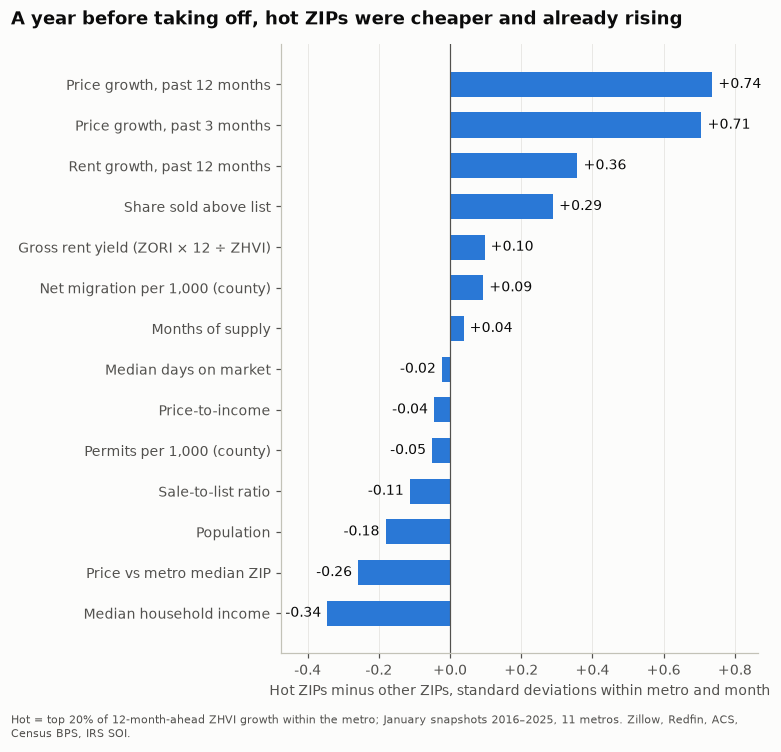

In [4]:
s = profile.sd_difference.rename(FEATURES)
fig, ax = c.ranked_bars(s, "{:+.2f}", FuncFormatter(lambda v, _: f"{v:+.1f}"))
ax.set_xlabel("Hot ZIPs minus other ZIPs, standard deviations within metro and month")
c.save(
    fig,
    "q5_hot_zip_profile",
    "A year before taking off, hot ZIPs were cheaper and already rising",
    "Hot = top 20% of 12-month-ahead ZHVI growth within the metro; January snapshots 2016–2025, 11 metros. "
    "Zillow, Redfin, ACS, Census BPS, IRS SOI.",
)

Hit rate by quintile: the share of ZIPs that turned hot, by the quintile they sat in within their metro and month
(Q1 = lowest value). With no signal every cell would be 20%.

In [5]:
quint = std.apply(
    lambda col: (
        col.groupby([z.cbsa_code, z.month])
        .rank(pct=True)
        .mul(5)
        .clip(upper=4.999)
        .floordiv(1)
        + 1
    )
)
hits = pd.DataFrame({f: z.hot.groupby(quint[f]).mean() for f in FEATURES}).T
hits.columns = [f"Q{int(q)}" for q in hits.columns]
hits.loc[profile.index].rename(FEATURES).style.format("{:.0%}").background_gradient(
    cmap="Blues", axis=None
)

,Q1,Q2,Q3,Q4,Q5
"Price growth, past 12 months",10%,11%,15%,21%,44%
"Price growth, past 3 months",10%,12%,14%,21%,43%
"Rent growth, past 12 months",10%,12%,14%,19%,23%
Median household income,36%,22%,15%,12%,16%
Share sold above list,19%,14%,15%,21%,31%
Price vs metro median ZIP,40%,21%,12%,12%,18%
Population,28%,20%,19%,17%,18%
Sale-to-list ratio,26%,18%,16%,17%,23%
Gross rent yield (ZORI × 12 ÷ ZHVI),21%,12%,10%,12%,24%
"Net migration per 1,000 (county)",21%,18%,20%,18%,24%


Stability: the standardized difference of the top features in each snapshot year.

In [6]:
top_features = list(profile.index[:4])
by_year = {}
for y in range(2016, 2026):
    yr = z.month.dt.year == y
    by_year[y] = (
        std[yr & z.hot].mean()[top_features] - std[yr & ~z.hot].mean()[top_features]
    )
pd.DataFrame(by_year).rename(FEATURES).round(2)

,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
"Price growth, past 12 months",1.31,1.34,1.18,1.07,1.04,-0.04,-0.27,0.09,0.73,0.93
"Price growth, past 3 months",1.06,1.15,0.87,1.05,0.74,0.34,0.04,0.44,0.45,0.91
"Rent growth, past 12 months",0.40,0.56,0.50,0.72,0.63,0.76,0.21,0.19,0.18,-0.03
Median household income,-1.01,-0.96,-1.04,-0.88,-0.87,0.69,-0.46,0.21,0.58,0.28


## Answer

In [7]:
f1, f2 = profile.index[:2]
h1, h2 = hits.loc[f1], hits.loc[f2]


def extreme(f, h):
    q = "Q1" if profile.sd_difference[f] < 0 else "Q5"
    return q, h[q]


q1_, r1 = extreme(f1, h1)
q2_, r2 = extreme(f2, h2)
print(
    f"A year before taking off, hot ZIPs differed most on {FEATURES[f1].lower()} ({profile.sd_difference[f1]:+.2f} SD) "
    f"and {FEATURES[f2].lower()} ({profile.sd_difference[f2]:+.2f} SD): ZIPs in their metro's {q1_} of the first turned "
    f"hot {r1:.0%} of the time and those in the {q2_} of the second {r2:.0%}, against a 20% base rate."
)
flipped = [y for y, v in by_year.items() if v[f1] <= 0]
print(
    f"The {FEATURES[f1].lower()} signal vanished or reversed in the {flipped} snapshots, whose windows ran through the 2021–2022 boom."
)

A year before taking off, hot ZIPs differed most on price growth, past 12 months (+0.74 SD) and price growth, past 3 months (+0.71 SD): ZIPs in their metro's Q5 of the first turned hot 44% of the time and those in the Q5 of the second 43%, against a 20% base rate.
The price growth, past 12 months signal vanished or reversed in the [2021, 2022] snapshots, whose windows ran through the 2021–2022 boom.
